# EDA Presentation: MNE Resilience & Natural Disasters
**Dyadic Panel 2008–2019 | FATS + EM-DAT + TiVA + CEPII + WDI/WGI**

This notebook generates exploratory plots for the thesis supervisor meeting.

**Data source:** `data/Silver/estimation_sample.parquet`  
**Two-strategy structure (must never be mixed):**
- **Strategy A** (`df_strategy_a`): `industry == "B-S_X_O"` — total manufacturing aggregate; used for geographic and time-series plots
- **Strategy B** (`df_strategy_b`): `nace_section.notna()` — section-letter NACE rows with GVC data; used for industry heterogeneity and GVC plots

---

In [1]:
import os
from pathlib import Path as _Path
# Run from the repository root, whether the kernel starts in notebooks/ or at the root
if _Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 100

# ── Load estimation sample (NaN→0 already applied in 08_create_estimation_sample.py) ─────
df = pd.read_parquet('data/Silver/estimation_sample.parquet')
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols")
print("Columns:", list(df.columns))

# ── Strategy sub-samples (must NOT be mixed) ─────────────────────────────────────
# Strategy A: total manufacturing aggregate — geographic / time-series plots
df_strategy_a = df[df['industry'] == 'B-S_X_O'].copy()
# Strategy B: section-letter NACE rows — industry heterogeneity & GVC plots
df_strategy_b = df[df['nace_section'].notna()].copy()

print(f"\nStrategy A (B-S_X_O):  {len(df_strategy_a):,} rows, "
      f"{df_strategy_a['host_country'].nunique()} host countries")
print(f"Strategy B (section):  {len(df_strategy_b):,} rows, "
      f"{df_strategy_b['nace_section'].nunique()} NACE sections")

# ── Severity columns in new schema ──────────────────────────────────────────
SEV_COLS = ['sev_sudden_physical', 'sev_seasonal_physical', 'sev_climatic_slow']
N_COLS   = [c for c in df.columns if c.startswith('n_')]

# ── Derived variables (panel-correct: sort then diff within dyad×industry) ────────
for _df in [df, df_strategy_a, df_strategy_b]:
    _df.sort_values(['home_country', 'host_country', 'industry', 'year'], inplace=True)

    _df['ln_emp'] = np.log(_df['emp'].clip(lower=1))
    _df['delta_ln_emp'] = (
        _df.groupby(['home_country', 'host_country', 'industry'])['ln_emp'].diff()
    )
    _df['ln_ent'] = np.log(_df['ent'])  # NaN when suppressed; -inf when ent==0 -> cleaned below
    _df['dln_ent'] = (
        _df.groupby(['home_country', 'host_country', 'industry'])['ln_ent'].diff()
    )
    _df['dln_ent'] = _df['dln_ent'].replace([np.inf, -np.inf], np.nan)

    # Composite severity (3 grouped severity measures, already imputed to 0)
    _df['severity_total'] = _df[SEV_COLS].sum(axis=1)

    # Crisis year: top 10th percentile of nonzero severity, within this sample
    _nz = _df.loc[_df['severity_total'] > 0, 'severity_total']
    _threshold_90 = _nz.quantile(0.90)
    _df['crisis_year'] = (_df['severity_total'] >= _threshold_90).astype(int)
    _df['crisis_label'] = _df['crisis_year'].map({0: 'Normal Year', 1: 'Crisis Year'})

# Deduplicated host-year slice for disaster-level aggregations (Strategy A base)
hy = df_strategy_a.drop_duplicates(subset=['host_country', 'year']).copy()

print(f"\ndelta_ln_emp non-NaN (df):             {df['delta_ln_emp'].notna().sum():,}")
print(f"crisis_year==1 (Strategy A):           {df_strategy_a['crisis_year'].sum():,}")
print(f"crisis_year==1 (Strategy B):           {df_strategy_b['crisis_year'].sum():,}")
print(f"Host countries (Strategy A, B-S_X_O): {df_strategy_a['host_country'].nunique()}")

Loaded: 107,775 rows × 45 cols
Columns: ['year', 'home_country', 'host_country', 'industry', 'emp', 'ent', 'tur', 'home_region', 'nace_section', 'n_animal_incident', 'n_drought', 'n_earthquake', 'n_epidemic', 'n_extreme_temperature', 'n_flood', 'n_impact', 'n_infestation', 'n_mass_movement_dry', 'n_mass_movement_wet', 'n_storm', 'n_volcanic_activity', 'n_wildfire', 'sev_sudden_physical', 'sev_seasonal_physical', 'sev_climatic_slow', 'total_missing_affected', 'hist_sev_static_host', 'hist_sev_dynamic_host', 'hist_cnt_static_host', 'hist_cnt_dynamic_host', 'hist_sev_static_home', 'hist_sev_dynamic_home', 'hist_cnt_static_home', 'hist_cnt_dynamic_home', 'distw', 'contig', 'colony', 'comlang_off', 'gdp_pc_host', 'pop_host', 'gdp_pc_home', 'pop_home', 'ge_host', 'ge_home', 'gvc_position']

Strategy A (B-S_X_O):  25,297 rows, 184 host countries
Strategy B (section):  71,535 rows, 17 NACE sections

delta_ln_emp non-NaN (df):             62,565
crisis_year==1 (Strategy A):           1,584
cris

### Supplementary: Missing Value Rates by Strategy
Shows which variables are missing and for which strategy. Key insight: `gvc_position` is 100% missing for Strategy A (B-S_X_O aggregate has no TiVA match) and ~17% missing for Strategy B (section-level rows).

---

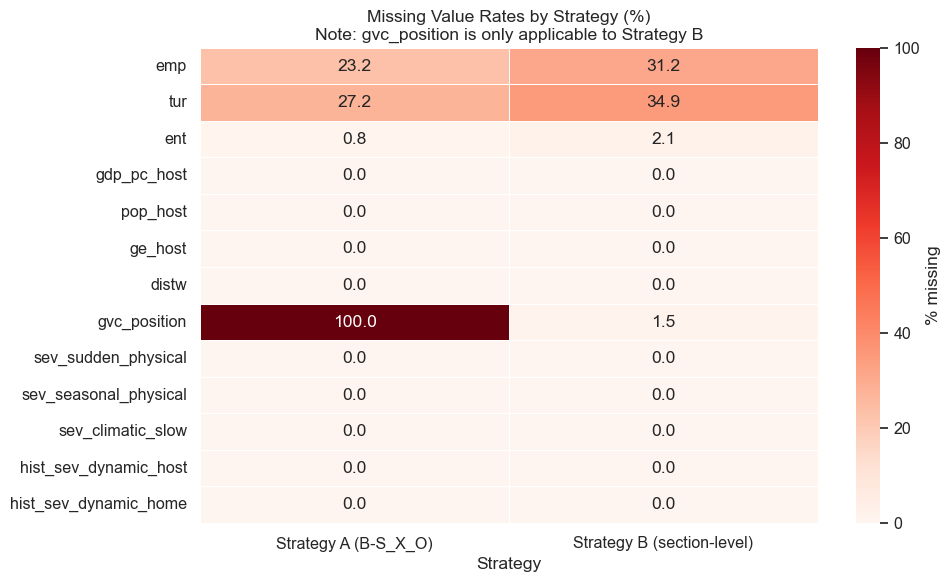

In [2]:
key_cols = ['emp', 'tur', 'ent', 'gdp_pc_host', 'pop_host', 'ge_host',
            'distw', 'gvc_position', 'sev_sudden_physical',
            'sev_seasonal_physical', 'sev_climatic_slow',
            'hist_sev_dynamic_host', 'hist_sev_dynamic_home']

miss_a = df_strategy_a[key_cols].isna().mean().rename('Strategy A (B-S_X_O)')
miss_b = df_strategy_b[key_cols].isna().mean().rename('Strategy B (section-level)')
miss_df = pd.concat([miss_a, miss_b], axis=1) * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(miss_df, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100,
            ax=ax, linewidths=0.5, cbar_kws={'label': '% missing'})
ax.set_title('Missing Value Rates by Strategy (%)\n'
             'Note: gvc_position is only applicable to Strategy B')
ax.set_xlabel('Strategy')
plt.tight_layout()
plt.show()

---
## Part 1: Setting the Scene (Macro Overview)

### Graph 1: Geographic Coverage of MNE Activity
**Title:** Total MNE Employment by Host Country (Average 2008–2019) — Strategy A

**Hypothesis / Purpose:** Show the geographic footprint of EU/EFTA outward affiliate employment using the total manufacturing aggregate (Strategy A, `B-S_X_O`). Validates geographic coverage.

Strategy A: 184 host countries in B-S_X_O sample


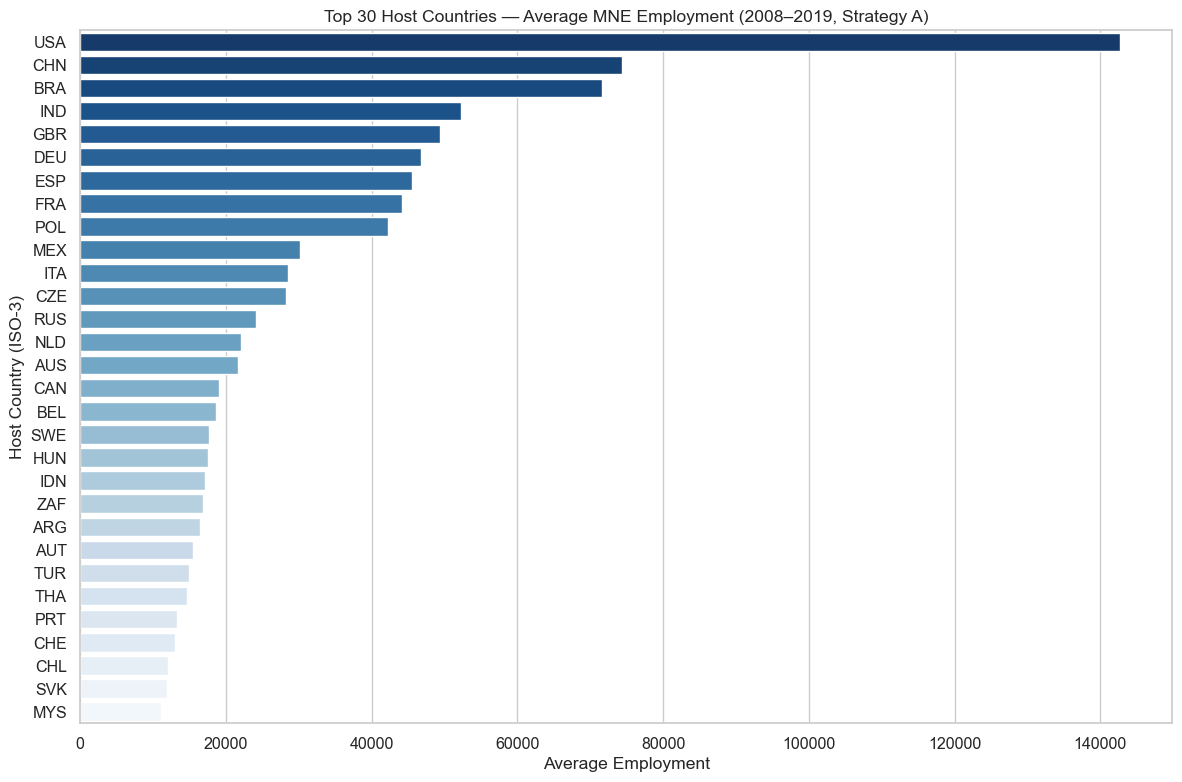

In [3]:
emp_by_host = df_strategy_a.groupby('host_country')['emp'].mean().reset_index()
# Filter to real 3-letter ISO-3 codes
emp_by_host = emp_by_host[
    emp_by_host['host_country'].str.len().eq(3) & emp_by_host['host_country'].str.isalpha()
]
print(f"Strategy A: {df_strategy_a['host_country'].nunique()} host countries in B-S_X_O sample")

try:
    import plotly.express as px
    fig = px.choropleth(
        emp_by_host,
        locations='host_country',
        locationmode='ISO-3',
        color=np.log1p(emp_by_host['emp']),
        color_continuous_scale='Blues',
        title=f'Average MNE Employment by Host Country (2008–2019, log scale) — Strategy A',
        labels={'color': 'log(avg emp + 1)'}
    )
    fig.update_layout(margin=dict(l=0, r=0, t=50, b=0), height=500)
    fig.show()
except ImportError:
    top30 = emp_by_host.nlargest(30, 'emp')
    plt.figure(figsize=(12, 8))
    sns.barplot(data=top30, y='host_country', x='emp', palette='Blues_r')
    plt.title('Top 30 Host Countries — Average MNE Employment (2008–2019, Strategy A)')
    plt.xlabel('Average Employment')
    plt.ylabel('Host Country (ISO-3)')
    plt.tight_layout()
    plt.show()

### Graph 2: Global Disaster Severity vs MNE Employment Over Time
**Title:** Global Sum of Total Affected vs Global MNE Employment (2008–2019)

**Hypothesis / Purpose:** Visualise whether aggregate disaster intensity co-moves with aggregate MNE activity. Strategy A base (B-S_X_O) provides a clean aggregate time-series. Severity = sum of `sev_sudden_physical + sev_seasonal_physical + sev_climatic_slow`.

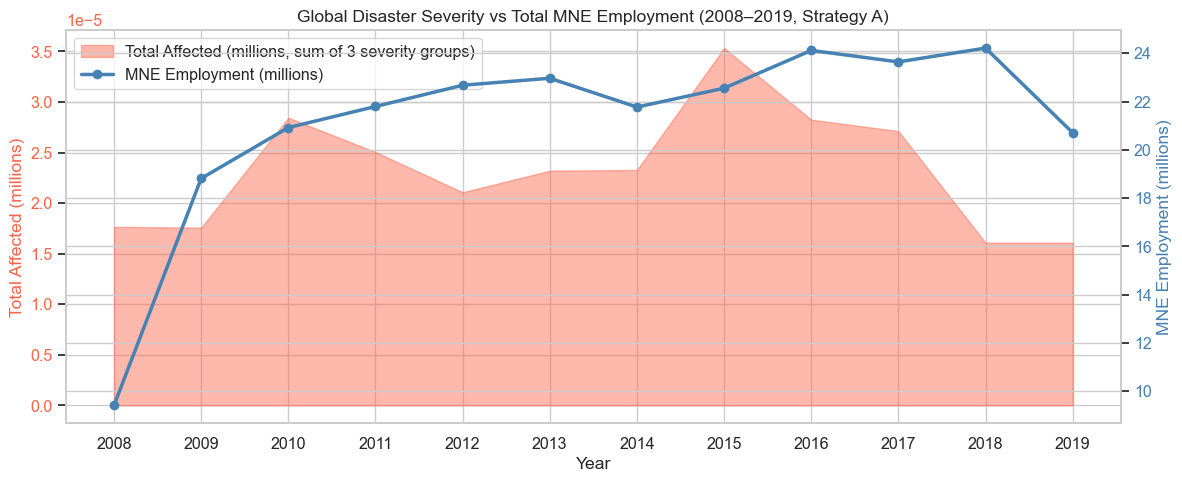

In [4]:
ts = df_strategy_a.groupby('year').agg(
    severity_sum=('severity_total', 'sum'),
    emp_sum=('emp', 'sum')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.fill_between(ts['year'], ts['severity_sum'] / 1e6, alpha=0.45, color='tomato',
                 label='Total Affected (millions, sum of 3 severity groups)')
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Affected (millions)', color='tomato')
ax1.tick_params(axis='y', labelcolor='tomato')
ax1.set_xticks(ts['year'])

ax2 = ax1.twinx()
ax2.plot(ts['year'], ts['emp_sum'] / 1e6, color='steelblue', linewidth=2.5,
         marker='o', label='MNE Employment (millions)')
ax2.set_ylabel('MNE Employment (millions)', color='steelblue')
ax2.tick_params(axis='y', labelcolor='steelblue')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.title('Global Disaster Severity vs Total MNE Employment (2008–2019, Strategy A)')
plt.tight_layout()
plt.show()

### Graph 3: Disaster Group Dominance — Historical Coverage
**Title:** Historical Frequency and Scale of Each Disaster Group

**Hypothesis / Purpose:** Show which disaster groups dominate the panel. Uses the three grouped severity measures: sudden physical (geo/volcanic/impact), seasonal physical (flood/storm/wildfire), and climatic slow-onset (drought/extreme temp).

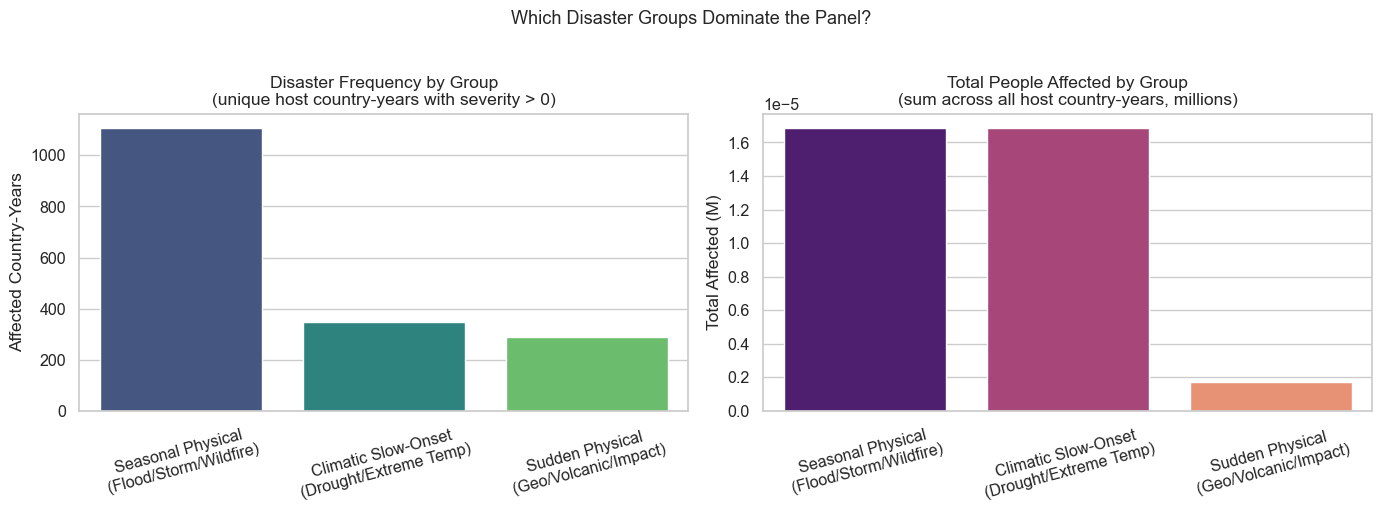

In [5]:
subgroup_map = {
    'Sudden Physical\n(Geo/Volcanic/Impact)': 'sev_sudden_physical',
    'Seasonal Physical\n(Flood/Storm/Wildfire)': 'sev_seasonal_physical',
    'Climatic Slow-Onset\n(Drought/Extreme Temp)': 'sev_climatic_slow',
}

# Use deduplicated host-year slice (Strategy A) to avoid counting affiliates separately
freq_data = []
for name, col in subgroup_map.items():
    freq_data.append({
        'Subgroup': name,
        'Affected Country-Years': int((hy[col] > 0).sum()),
        'Total Affected (M)': hy[col].sum() / 1e6
    })
freq_df = pd.DataFrame(freq_data).sort_values('Affected Country-Years', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=freq_df, x='Subgroup', y='Affected Country-Years',
            ax=axes[0], palette='viridis', order=freq_df['Subgroup'])
axes[0].set_title('Disaster Frequency by Group\n(unique host country-years with severity > 0)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_xlabel('')

sns.barplot(data=freq_df, x='Subgroup', y='Total Affected (M)',
            ax=axes[1], palette='magma', order=freq_df['Subgroup'])
axes[1].set_title('Total People Affected by Group\n(sum across all host country-years, millions)')
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_xlabel('')

plt.suptitle('Which Disaster Groups Dominate the Panel?', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Graph 4: Correlation Matrix of Key Continuous Variables
**Title:** Pairwise Correlations — Δln(emp), Governance, GDP, GVC Position, Distance

**Hypothesis / Purpose:** Identify multicollinearity risks before regression. Uses Strategy B (section-level rows) for GVC coverage. `gvc_position` is the KWW (2014) index: ln(1+fwd/100) − ln(1+bwd/100); >0 = upstream.

Correlation matrix on 38,776 complete observations (Strategy B)


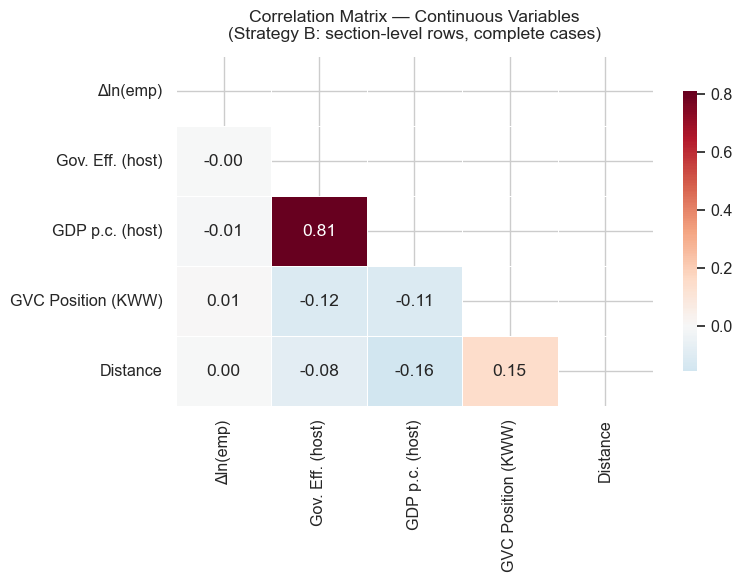

In [6]:
CORR_COLS = [
    'delta_ln_emp', 'ge_host', 'gdp_pc_host',
    'gvc_position', 'distw'
]
corr_labels = [
    'Δln(emp)', 'Gov. Eff. (host)', 'GDP p.c. (host)',
    'GVC Position (KWW)', 'Distance'
]
corr_df = df_strategy_b[CORR_COLS].dropna()
print(f"Correlation matrix on {len(corr_df):,} complete observations (Strategy B)")

mask = np.triu(np.ones_like(corr_df.corr(), dtype=bool))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
    mask=mask, xticklabels=corr_labels, yticklabels=corr_labels,
    ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8}
)
ax.set_title('Correlation Matrix — Continuous Variables\n'
             '(Strategy B: section-level rows, complete cases)', pad=12)
plt.tight_layout()
plt.show()

---
## Part 2: The Direct Shock (Disaster vs. Affiliate Activity)

### Graph 5: Sudden Physical Shocks vs Employment Growth
**Title:** log(1 + Total Affected — Sudden Physical Shocks) vs Δln(Employment)

**Hypothesis / Purpose:** Test whether sudden physical disaster severity (`sev_sudden_physical`: geophysical + volcanic + impact) negatively predicts affiliate employment growth. Strategy A provides widest coverage.

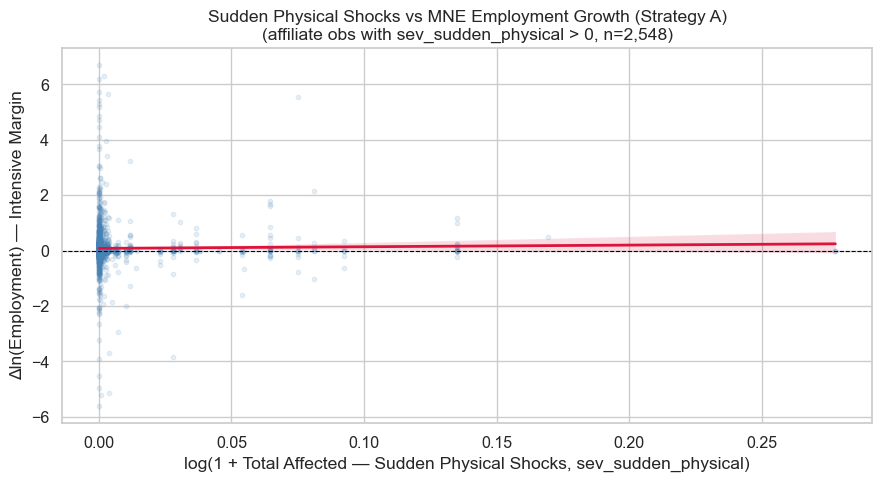

In [7]:
plot5 = df_strategy_a[df_strategy_a['sev_sudden_physical'] > 0][
    ['sev_sudden_physical', 'delta_ln_emp']
].dropna().copy()
plot5['log_sev'] = np.log1p(plot5['sev_sudden_physical'])

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=plot5, x='log_sev', y='delta_ln_emp',
    scatter_kws={'alpha': 0.12, 's': 10, 'color': 'steelblue'},
    line_kws={'color': 'crimson', 'linewidth': 2},
    ax=ax
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('log(1 + Total Affected — Sudden Physical Shocks, sev_sudden_physical)')
ax.set_ylabel('Δln(Employment) — Intensive Margin')
ax.set_title(
    f'Sudden Physical Shocks vs MNE Employment Growth (Strategy A)\n'
    f'(affiliate obs with sev_sudden_physical > 0, n={len(plot5):,})'
)
plt.tight_layout()
plt.show()

### Graph 6: Seasonal Physical Shocks vs Employment Growth
**Title:** log(1 + Total Affected — Seasonal Physical Shocks) vs Δln(Employment)

**Hypothesis / Purpose:** Test whether seasonal physical disaster severity (`sev_seasonal_physical`: flood + storm + wildfire) predicts affiliate employment growth differently from sudden physical shocks.

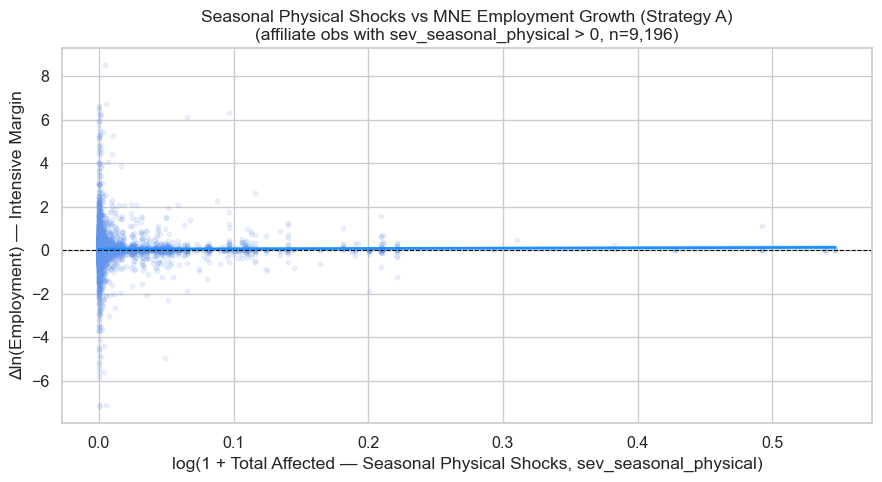

In [8]:
plot6 = df_strategy_a[df_strategy_a['sev_seasonal_physical'] > 0][
    ['sev_seasonal_physical', 'delta_ln_emp']
].dropna().copy()
plot6['log_sev'] = np.log1p(plot6['sev_seasonal_physical'])

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=plot6, x='log_sev', y='delta_ln_emp',
    scatter_kws={'alpha': 0.12, 's': 10, 'color': 'cornflowerblue'},
    line_kws={'color': 'dodgerblue', 'linewidth': 2},
    ax=ax
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('log(1 + Total Affected — Seasonal Physical Shocks, sev_seasonal_physical)')
ax.set_ylabel('Δln(Employment) — Intensive Margin')
ax.set_title(
    f'Seasonal Physical Shocks vs MNE Employment Growth (Strategy A)\n'
    f'(affiliate obs with sev_seasonal_physical > 0, n={len(plot6):,})'
)
plt.tight_layout()
plt.show()

### Graph 7: Intensive Margin — Crisis vs Normal Years
**Title:** Distribution of Δln(Employment) in Crisis Years vs Normal Years

**Hypothesis:** The distribution of employment growth shifts downward during crisis years, with more mass in the left tail (large employment drops).

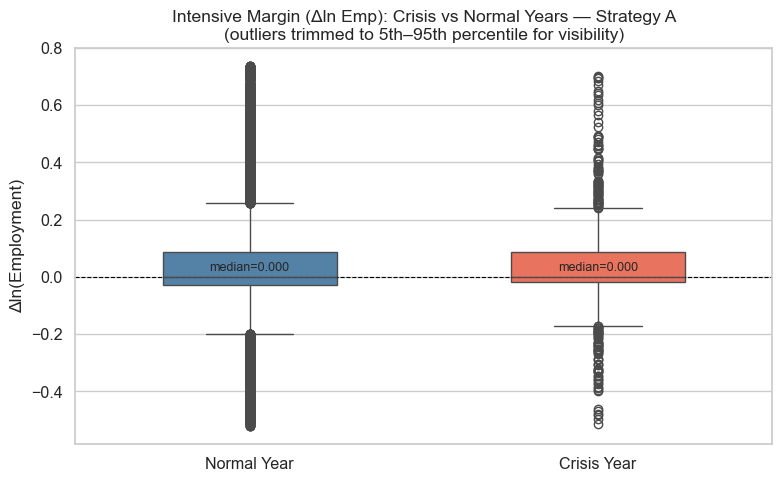

In [9]:
plot7 = df_strategy_a[['delta_ln_emp', 'crisis_label']].dropna().copy()
q05, q95 = plot7['delta_ln_emp'].quantile([0.05, 0.95])
plot7 = plot7[(plot7['delta_ln_emp'] >= q05) & (plot7['delta_ln_emp'] <= q95)]

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=plot7, x='crisis_label', y='delta_ln_emp',
    palette={'Normal Year': 'steelblue', 'Crisis Year': 'tomato'},
    order=['Normal Year', 'Crisis Year'], width=0.5, ax=ax
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title(
    'Intensive Margin (Δln Emp): Crisis vs Normal Years — Strategy A\n'
    '(outliers trimmed to 5th–95th percentile for visibility)'
)
ax.set_xlabel('')
ax.set_ylabel('Δln(Employment)')

for i, label in enumerate(['Normal Year', 'Crisis Year']):
    med = plot7[plot7['crisis_label'] == label]['delta_ln_emp'].median()
    ax.text(i, med + 0.01, f'median={med:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Graph 8: Extensive Margin — Crisis vs Normal Years
**Title:** Distribution of % Change in Enterprises in Crisis Years vs Normal Years

**Hypothesis:** The probability of affiliate exit increases in crisis years, showing up as a leftward shift in the % change in enterprise counts.

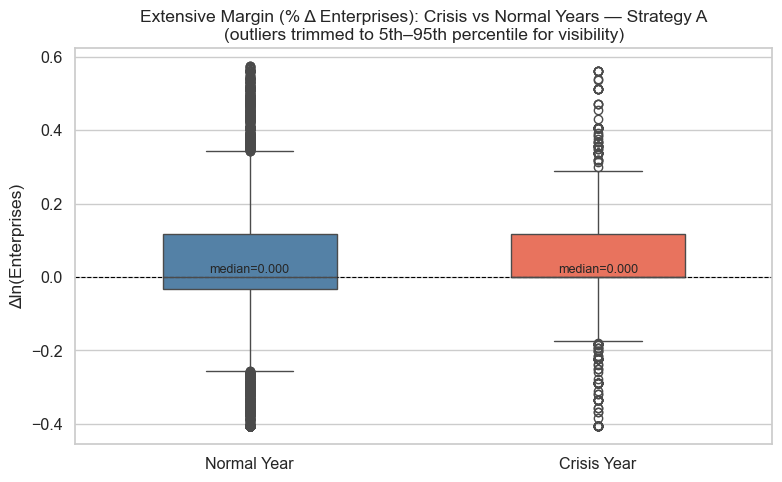

In [10]:
plot8 = df_strategy_a[['dln_ent', 'crisis_label']].dropna().copy()
q05, q95 = plot8['dln_ent'].quantile([0.05, 0.95])
plot8 = plot8[(plot8['dln_ent'] >= q05) & (plot8['dln_ent'] <= q95)]

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=plot8, x='crisis_label', y='dln_ent',
    palette={'Normal Year': 'steelblue', 'Crisis Year': 'tomato'},
    order=['Normal Year', 'Crisis Year'], width=0.5, ax=ax
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title(
    'Extensive Margin (% Δ Enterprises): Crisis vs Normal Years — Strategy A\n'
    '(outliers trimmed to 5th–95th percentile for visibility)'
)
ax.set_xlabel('')
ax.set_ylabel('Δln(Enterprises)')

for i, label in enumerate(['Normal Year', 'Crisis Year']):
    med = plot8[plot8['crisis_label'] == label]['dln_ent'].median()
    ax.text(i, med + 0.003, f'median={med:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Graph 9: Event Study — Employment Response around Major Sudden Physical Shocks
**Title:** Average Δln(Employment) at T−2 to T+3 relative to major sudden physical shock onset

**Hypothesis / Purpose:** Identify whether the employment response is immediate or lagged. Strategy A ensures consistent industry coverage. Lags are panel-correct: `delta_ln_emp` is differenced within `(home, host, industry)` groups.

Major sudden physical shock obs: 382 (threshold: 0 affected)
 rel_year     mean   n
       -2 0.033841 196
       -1 0.057741 220
        0 0.044811 248
        1 0.019606 241
        2 0.090549 219
        3 0.058297 209


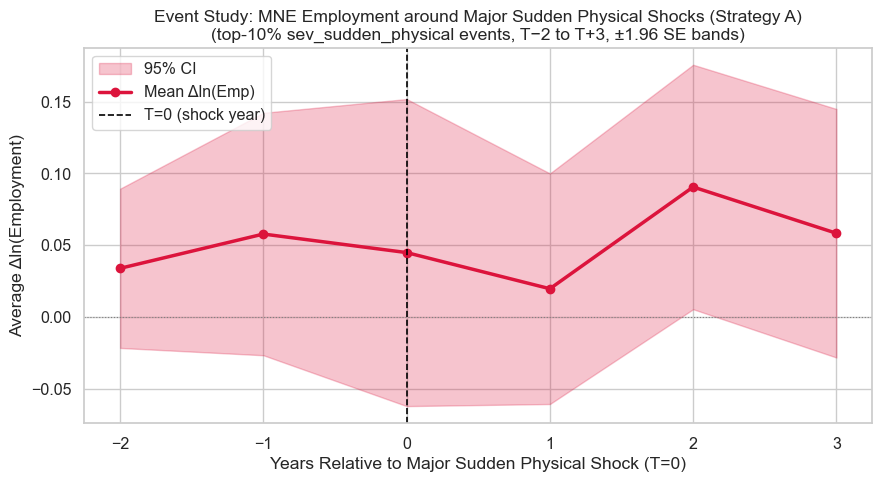

In [11]:
# Top 10th percentile of nonzero sev_sudden_physical
geo_q90 = df_strategy_a.loc[
    df_strategy_a['sev_sudden_physical'] > 0, 'sev_sudden_physical'
].quantile(0.90)

shock_events = (
    df_strategy_a[df_strategy_a['sev_sudden_physical'] >= geo_q90]
    [['home_country', 'host_country', 'year']]
    .drop_duplicates()
    .rename(columns={'year': 'shock_year'})
)
print(f"Major sudden physical shock obs: {len(shock_events):,} (threshold: {geo_q90:,.0f} affected)")

event_df = df_strategy_a.merge(shock_events, on=['home_country', 'host_country'], how='inner')
event_df['rel_year'] = event_df['year'] - event_df['shock_year']
event_df = event_df[(event_df['rel_year'] >= -2) & (event_df['rel_year'] <= 3)]

es = (
    event_df.groupby('rel_year')['delta_ln_emp']
    .agg(['mean', 'sem', 'count'])
    .reset_index()
)
es.columns = ['rel_year', 'mean', 'se', 'n']
es['ci_lo'] = es['mean'] - 1.96 * es['se']
es['ci_hi'] = es['mean'] + 1.96 * es['se']
print(es[['rel_year', 'mean', 'n']].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(es['rel_year'], es['ci_lo'], es['ci_hi'],
                alpha=0.25, color='crimson', label='95% CI')
ax.plot(es['rel_year'], es['mean'], marker='o', color='crimson',
        linewidth=2.5, label='Mean Δln(Emp)')
ax.axvline(0, color='black', linewidth=1.2, linestyle='--', label='T=0 (shock year)')
ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax.set_xticks(range(-2, 4))
ax.set_xlabel('Years Relative to Major Sudden Physical Shock (T=0)')
ax.set_ylabel('Average Δln(Employment)')
ax.set_title(
    'Event Study: MNE Employment around Major Sudden Physical Shocks (Strategy A)\n'
    '(top-10% sev_sudden_physical events, T−2 to T+3, ±1.96 SE bands)'
)
ax.legend()
plt.tight_layout()
plt.show()

---
## Part 3: The Moderating Role of GVCs (The Core Contribution)

### Graph 10: GVC Position Index by NACE Section
**Title:** Distribution of `gvc_position` (KWW 2014) across NACE Rev.2 Sections — Strategy B

**Hypothesis / Purpose:** Confirm that the GVC Position Index captures genuine cross-industry variation: positive values indicate upstream (forward-integrated) industries; negative values indicate downstream (assembly-intensive) industries. Validates the measure before using it as a moderator.

Coverage: 17 sections, 70,465 obs
nace_section
I   -0.126
Q   -0.044
R   -0.043
S   -0.026
P   -0.024
C    0.015
L    0.041
H    0.185
F    0.188
A    0.197
G    0.246
J    0.260
E    0.261
K    0.322
M    0.368
N    0.368
B    0.438
Name: gvc_position, dtype: float64


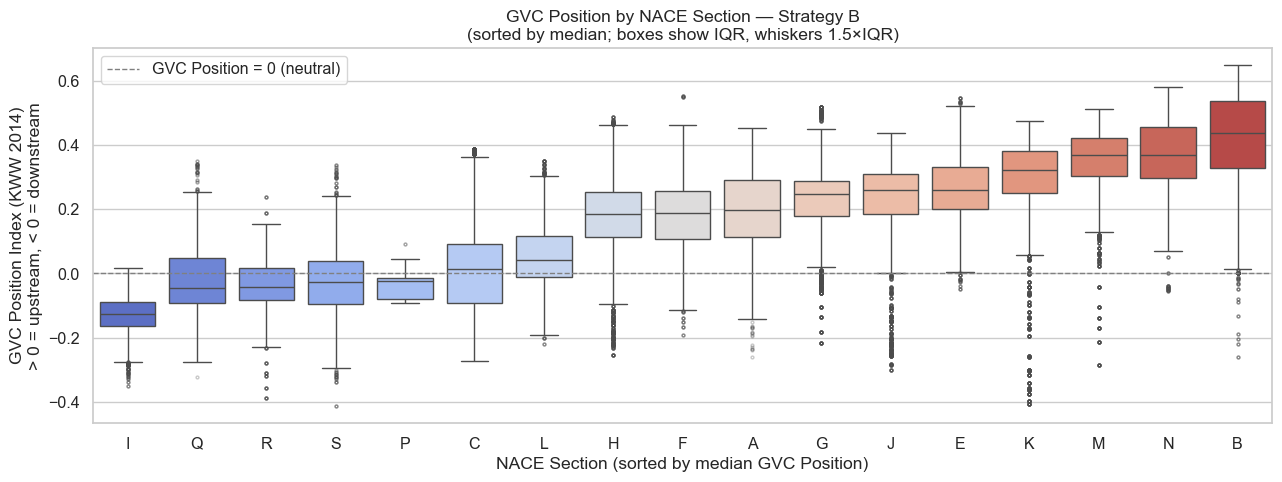

In [12]:
# Distribution of gvc_position by NACE section (Strategy B only)
gvc_sec = df_strategy_b.dropna(subset=['gvc_position'])
order = (
    gvc_sec.groupby('nace_section')['gvc_position']
    .median().sort_values().index.tolist()
)

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(
    data=gvc_sec,
    x='nace_section', y='gvc_position',
    order=order, palette='coolwarm', ax=ax,
    flierprops=dict(marker='o', markersize=2, alpha=0.3)
)
ax.axhline(0, color='gray', linestyle='--', linewidth=1.0, label='GVC Position = 0 (neutral)')
ax.set_xlabel('NACE Section (sorted by median GVC Position)')
ax.set_ylabel('GVC Position Index (KWW 2014)\n> 0 = upstream, < 0 = downstream')
ax.set_title('GVC Position by NACE Section — Strategy B\n'
             '(sorted by median; boxes show IQR, whiskers 1.5×IQR)')
ax.legend()
print(f"Coverage: {gvc_sec['nace_section'].nunique()} sections, {len(gvc_sec):,} obs")
print(gvc_sec.groupby('nace_section')['gvc_position'].median().sort_values().round(3))
plt.tight_layout()
plt.show()

### Graph 11: GVC Position & Employment Response in Crisis Years
**Title:** Average Δln(Employment) during Crisis Years — High vs Low GVC Position (median split)

**Hypothesis:** Upstream affiliates (high GVC Position) are harder to substitute in supply chains, so they show smaller employment drops during crises.

                         Group     mean       se    n
 High GVC Position\n(Upstream) 0.043292 0.030014 1266
Low GVC Position\n(Downstream) 0.051775 0.026583 1208


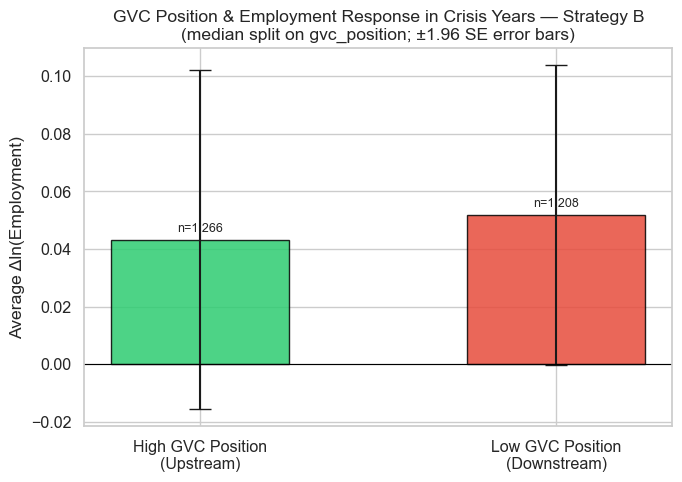

In [13]:
crisis_sec = df_strategy_b[df_strategy_b['crisis_year'] == 1].copy()
med_gvc = crisis_sec['gvc_position'].median()
crisis_sec['gvc_group'] = np.where(
    crisis_sec['gvc_position'] >= med_gvc,
    'High GVC Position\n(Upstream)',
    'Low GVC Position\n(Downstream)'
)

agg11 = (
    crisis_sec.dropna(subset=['gvc_position'])
    .groupby('gvc_group')['delta_ln_emp']
    .agg(['mean', 'sem', 'count'])
    .reset_index()
)
agg11.columns = ['Group', 'mean', 'se', 'n']
print(agg11.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
colors = {'High GVC Position\n(Upstream)': '#2ecc71', 'Low GVC Position\n(Downstream)': '#e74c3c'}
for _, row in agg11.iterrows():
    ax.bar(row['Group'], row['mean'], yerr=row['se'] * 1.96, capsize=8,
           color=colors[row['Group']], alpha=0.85, edgecolor='black', width=0.5)
    ax.text(row['Group'], row['mean'] + (0.002 if row['mean'] >= 0 else -0.004),
            f"n={row['n']:,}", ha='center', va='bottom', fontsize=9)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(
    'GVC Position & Employment Response in Crisis Years — Strategy B\n'
    '(median split on gvc_position; ±1.96 SE error bars)'
)
ax.set_ylabel('Average Δln(Employment)')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

### Graph 12: Upstream vs Downstream GVC Position & Employment Response
**Title:** Average Δln(Employment) during Crisis Years — Positive vs Negative GVC Position

**Hypothesis:** GVC Position > 0 (upstream/forward-integrated) affiliates show lower employment losses during crises than GVC Position < 0 (downstream/assembly) affiliates.

                        Group     mean       se    n
Downstream (gvc_position < 0) 0.044872 0.044093  389
  Upstream (gvc_position ≥ 0) 0.047912 0.022397 2085


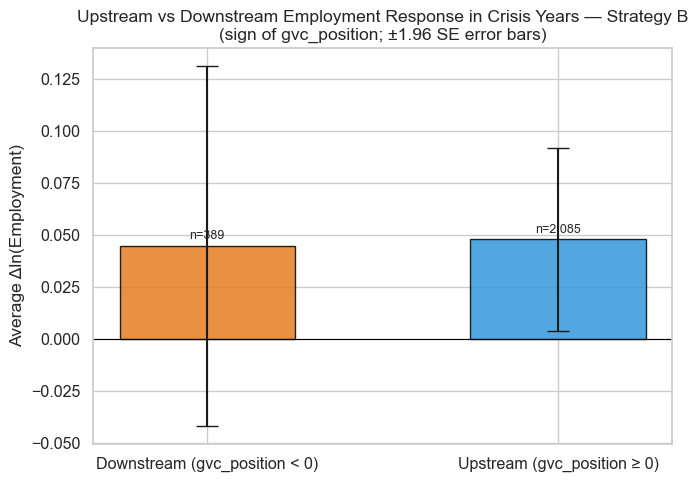

In [14]:
# Split on sign of gvc_position: positive = upstream, negative = downstream
crisis_sec2 = df_strategy_b[df_strategy_b['crisis_year'] == 1].dropna(subset=['gvc_position']).copy()
crisis_sec2['position_type'] = np.where(
    crisis_sec2['gvc_position'] >= 0,
    'Upstream (gvc_position ≥ 0)',
    'Downstream (gvc_position < 0)'
)

agg12 = (
    crisis_sec2.groupby('position_type')['delta_ln_emp']
    .agg(['mean', 'sem', 'count'])
    .reset_index()
)
agg12.columns = ['Group', 'mean', 'se', 'n']
print(agg12.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
colors = {'Upstream (gvc_position ≥ 0)': '#3498db', 'Downstream (gvc_position < 0)': '#e67e22'}
for _, row in agg12.iterrows():
    ax.bar(row['Group'], row['mean'], yerr=row['se'] * 1.96, capsize=8,
           color=colors[row['Group']], alpha=0.85, edgecolor='black', width=0.5)
    ax.text(row['Group'], row['mean'] + (0.002 if row['mean'] >= 0 else -0.004),
            f"n={row['n']:,}", ha='center', va='bottom', fontsize=9)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(
    'Upstream vs Downstream Employment Response in Crisis Years — Strategy B\n'
    '(sign of gvc_position; ±1.96 SE error bars)'
)
ax.set_ylabel('Average Δln(Employment)')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

### Graph 13: GVC Position & Firm Exit after a Major Shock
**Title:** % Change in Enterprises post-shock — Top vs Bottom Quartile GVC Position

**Hypothesis:** Affiliates in highly upstream industries (top quartile GVC Position) are retained because they are difficult to replace; downstream/assembly affiliates exit more readily.

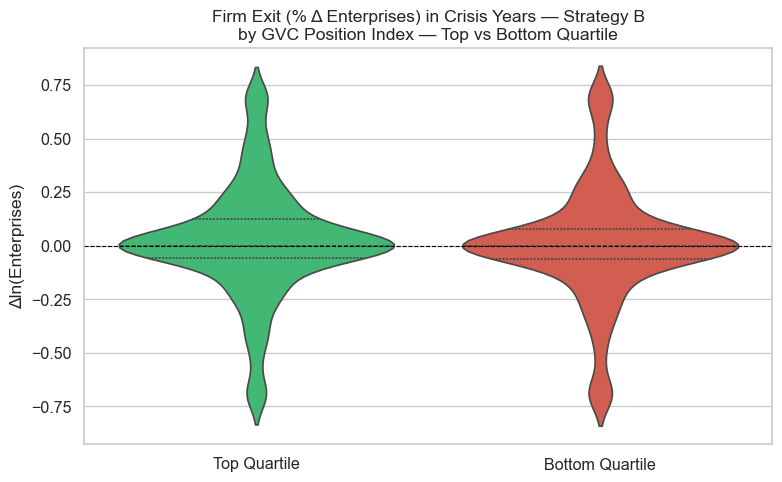

In [15]:
crisis_all = df_strategy_b[df_strategy_b['crisis_year'] == 1].copy()
q25 = crisis_all['gvc_position'].quantile(0.25)
q75 = crisis_all['gvc_position'].quantile(0.75)

violindf = crisis_all[crisis_all['gvc_position'].notna()].copy()
violindf['GVC Quartile'] = pd.cut(
    violindf['gvc_position'],
    bins=[-np.inf, q25, q75, np.inf],
    labels=['Bottom Quartile', 'Middle', 'Top Quartile']
)
violindf = violindf[violindf['GVC Quartile'].isin(['Bottom Quartile', 'Top Quartile'])]
violindf['GVC Quartile'] = violindf['GVC Quartile'].astype(str)
violindf = violindf.dropna(subset=['dln_ent'])

q05, q95 = violindf['dln_ent'].quantile([0.05, 0.95])
violindf = violindf[(violindf['dln_ent'] >= q05) & (violindf['dln_ent'] <= q95)]

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(
    data=violindf, x='GVC Quartile', y='dln_ent',
    palette={'Bottom Quartile': '#e74c3c', 'Top Quartile': '#2ecc71'},
    inner='quartile', ax=ax
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title(
    'Firm Exit (% Δ Enterprises) in Crisis Years — Strategy B\n'
    'by GVC Position Index — Top vs Bottom Quartile'
)
ax.set_ylabel('Δln(Enterprises)')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

### Graph 14: GVC Position vs Employment Volatility by Industry
**Title:** Average GVC Position vs Standard Deviation of Δln(Employment), by NACE Section

**Hypothesis:** More upstream industries (higher GVC Position) exhibit lower employment volatility because affiliates are embedded in long-term production networks.

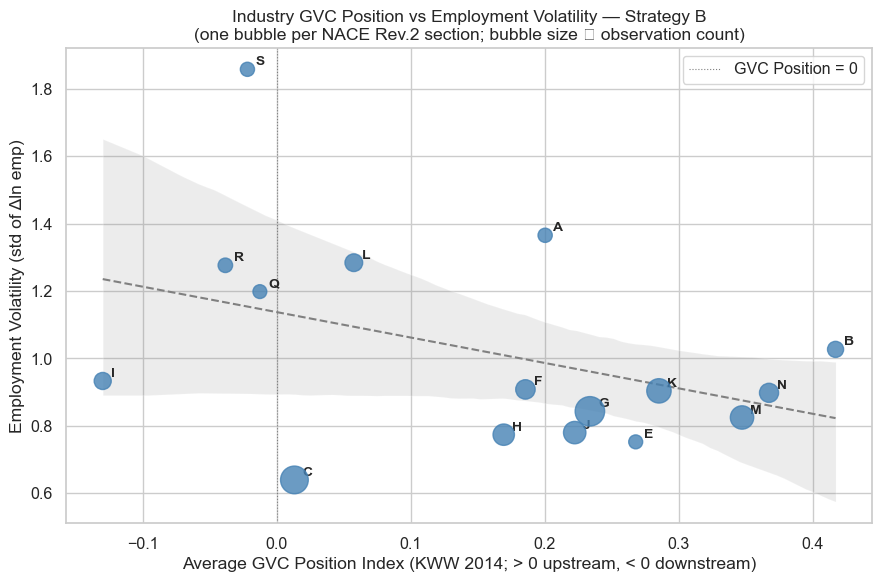

In [16]:
ind_agg = (
    df_strategy_b.groupby('nace_section')
    .agg(
        avg_gvc=('gvc_position', 'mean'),
        vol_emp=('delta_ln_emp', 'std'),
        n=('delta_ln_emp', 'count')
    )
    .reset_index()
    .dropna()
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(
    data=ind_agg, x='avg_gvc', y='vol_emp',
    scatter=False, line_kws={'color': 'gray', 'linestyle': '--', 'linewidth': 1.5}, ax=ax
)
ax.scatter(
    ind_agg['avg_gvc'], ind_agg['vol_emp'],
    s=ind_agg['n'] / ind_agg['n'].max() * 400 + 50,
    color='steelblue', alpha=0.8, zorder=5
)
for _, row in ind_agg.iterrows():
    ax.annotate(
        row['nace_section'],
        (row['avg_gvc'], row['vol_emp']),
        textcoords='offset points', xytext=(6, 3), fontsize=10, fontweight='bold'
    )
ax.axvline(0, color='gray', linewidth=0.8, linestyle=':', label='GVC Position = 0')
ax.set_xlabel('Average GVC Position Index (KWW 2014; > 0 upstream, < 0 downstream)')
ax.set_ylabel('Employment Volatility (std of Δln emp)')
ax.set_title(
    'Industry GVC Position vs Employment Volatility — Strategy B\n'
    '(one bubble per NACE Rev.2 section; bubble size ∝ observation count)'
)
ax.legend()
plt.tight_layout()
plt.show()

---
## Part 4: Host Country Characteristics (Institutions & Vulnerability)

### Graph 15: Governance Quality as a Moderator of Disaster Shocks
**Title:** Average Δln(Employment) by Crisis Year × Host Governance (ge_host median split)

**Hypothesis:** Good institutions (high government effectiveness) mitigate the employment impact of natural disasters through faster emergency response and more resilient infrastructure.

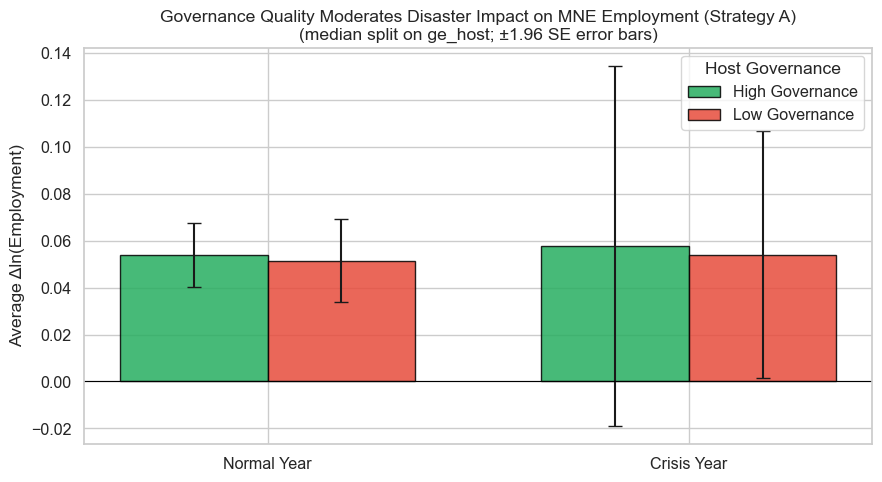

In [17]:
med_ge = df_strategy_a['ge_host'].median()
df_strategy_a['ge_group'] = np.where(
    df_strategy_a['ge_host'] >= med_ge, 'High Governance', 'Low Governance'
)

agg15 = (
    df_strategy_a.dropna(subset=['ge_host'])
    .groupby(['crisis_label', 'ge_group'])['delta_ln_emp']
    .agg(['mean', 'sem'])
    .reset_index()
)
agg15.columns = ['Crisis', 'Governance', 'mean', 'se']

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(2)
width = 0.35
order = ['Normal Year', 'Crisis Year']
gov_colors = {'High Governance': '#27ae60', 'Low Governance': '#e74c3c'}

for i, gov in enumerate(['High Governance', 'Low Governance']):
    sub = (
        agg15[agg15['Governance'] == gov]
        .set_index('Crisis')
        .reindex(order)
    )
    offset = (i - 0.5) * width
    ax.bar(x + offset, sub['mean'], width,
           yerr=sub['se'] * 1.96, capsize=5,
           label=gov, color=gov_colors[gov], alpha=0.85, edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(order)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(
    'Governance Quality Moderates Disaster Impact on MNE Employment (Strategy A)\n'
    '(median split on ge_host; ±1.96 SE error bars)'
)
ax.set_ylabel('Average Δln(Employment)')
ax.legend(title='Host Governance')
plt.tight_layout()
plt.show()

### Graph 16: Historical Host Exposure vs Employment Resilience in Crises
**Title:** `hist_n_static_host` vs Average Δln(Employment) during Crisis Years (by Host Country)

**Hypothesis:** Countries with high historical disaster exposure (events per capita 1988–2008) have built adaptive capacity, so their MNE affiliates suffer smaller employment drops in new disaster years.

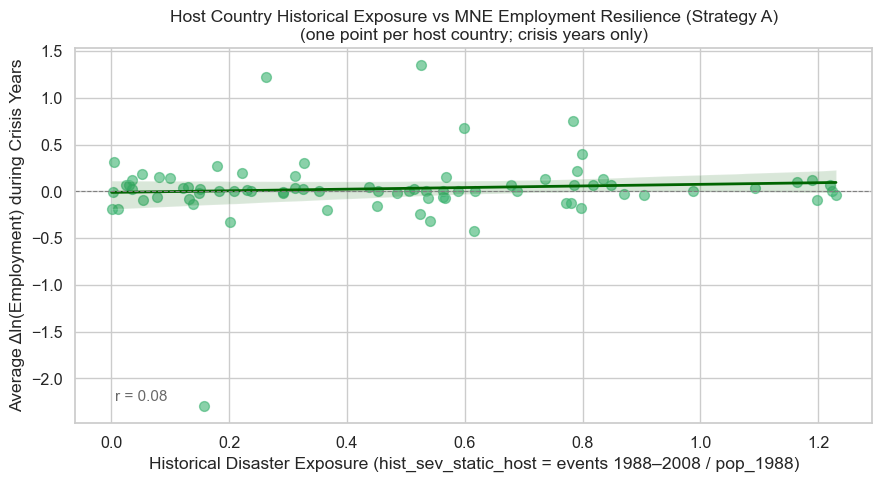

In [18]:
host_crisis = df_strategy_a[df_strategy_a['crisis_year'] == 1].copy()
host_agg16 = (
    host_crisis
    .groupby('host_country')
    .agg(
        hist_exp=('hist_sev_static_host', 'mean'),
        drop_emp=('delta_ln_emp', 'mean'),
        n=('delta_ln_emp', 'count')
    )
    .dropna()
    .reset_index()
)
host_agg16 = host_agg16[
    host_agg16['host_country'].str.len().eq(3) & host_agg16['host_country'].str.isalpha()
]

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=host_agg16, x='hist_exp', y='drop_emp',
    scatter_kws={'alpha': 0.6, 's': 50, 'color': 'mediumseagreen'},
    line_kws={'color': 'darkgreen', 'linewidth': 2},
    ax=ax
)
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Historical Disaster Exposure (hist_sev_static_host = events 1988–2008 / pop_1988)')
ax.set_ylabel('Average Δln(Employment) during Crisis Years')
ax.set_title(
    'Host Country Historical Exposure vs MNE Employment Resilience (Strategy A)\n'
    '(one point per host country; crisis years only)'
)

corr16 = host_agg16[['hist_exp', 'drop_emp']].corr().iloc[0, 1]
ax.text(0.05, 0.05, f'r = {corr16:.2f}', transform=ax.transAxes,
        fontsize=11, va='bottom', color='dimgray')
plt.tight_layout()
plt.show()

### Graph 16b: Investor Region vs Domestic Disaster History
**Title:** Distribution of `hist_n_static_home` by European Home Region

**Hypothesis:** Investors from S. Europe and E. Europe have higher domestic disaster exposure histories, making them inherently more “disaster-aware”. This could moderate their response to host-country shocks if accumulated experience builds institutional resilience.

**Note:** `hist_n_static_home` = count(events 1988–2008) / pop_1988 for the home country. Time-invariant per country; one point per home country is shown.

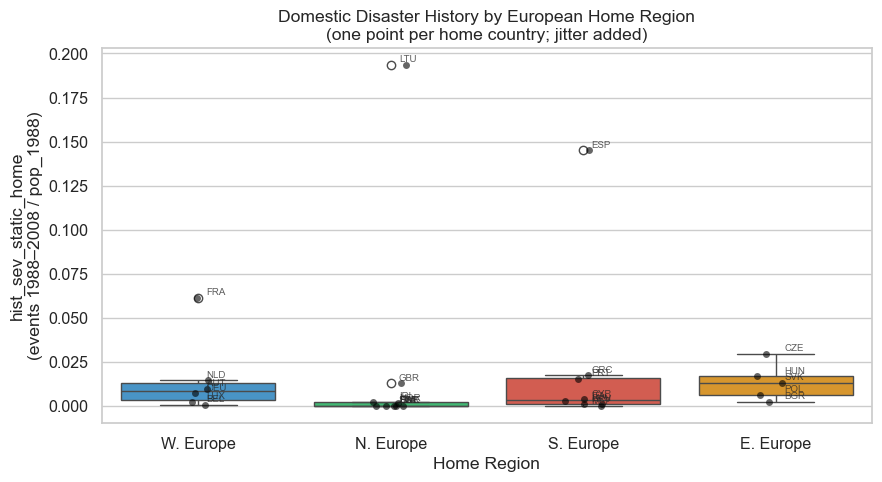


Descriptive statistics by home region:
             count    mean     std     min     25%     50%     75%     max
home_region                                                               
E. Europe      5.0  0.0138  0.0105  0.0025  0.0065  0.0131  0.0170  0.0298
N. Europe      9.0  0.0235  0.0639  0.0001  0.0001  0.0002  0.0026  0.1936
S. Europe      8.0  0.0234  0.0497  0.0000  0.0013  0.0034  0.0160  0.1452
W. Europe      6.0  0.0161  0.0228  0.0009  0.0036  0.0085  0.0134  0.0615


In [19]:
# One observation per home_country (time-invariant static measure)
home_exp = (
    df_strategy_a
    .groupby(['home_country', 'home_region'])['hist_sev_static_home']
    .first()
    .reset_index()
    .dropna()
)

region_order = ['W. Europe', 'N. Europe', 'S. Europe', 'E. Europe']
palette = {'W. Europe': '#3498db', 'N. Europe': '#2ecc71',
           'S. Europe': '#e74c3c', 'E. Europe': '#f39c12'}

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=home_exp,
    x='home_region', y='hist_sev_static_home',
    order=region_order, palette=palette, ax=ax,
    showfliers=True
)
sns.stripplot(
    data=home_exp,
    x='home_region', y='hist_sev_static_home',
    order=region_order, color='black', alpha=0.6, size=5, jitter=True, ax=ax
)
for _, row in home_exp.iterrows():
    if row['home_region'] in region_order:
        xi = region_order.index(row['home_region'])
        ax.annotate(row['home_country'], (xi, row['hist_sev_static_home']),
                    textcoords='offset points', xytext=(6, 2), fontsize=7, alpha=0.75)

ax.set_xlabel('Home Region')
ax.set_ylabel('hist_sev_static_home\n(events 1988–2008 / pop_1988)')
ax.set_title('Domestic Disaster History by European Home Region\n'
             '(one point per home country; jitter added)')
plt.tight_layout()
plt.show()

print('\nDescriptive statistics by home region:')
print(home_exp.groupby('home_region')['hist_sev_static_home'].describe().round(4))

### Graph 17: Development Level vs Disaster Severity
**Title:** log(GDP per Capita, host) vs log(1 + Total Affected) — Hexbin Density

**Hypothesis / Purpose:** Richer countries may experience fewer large-scale disasters (less vulnerability) or may have better reporting. The hexbin reveals the joint distribution and any development-vulnerability gradient.

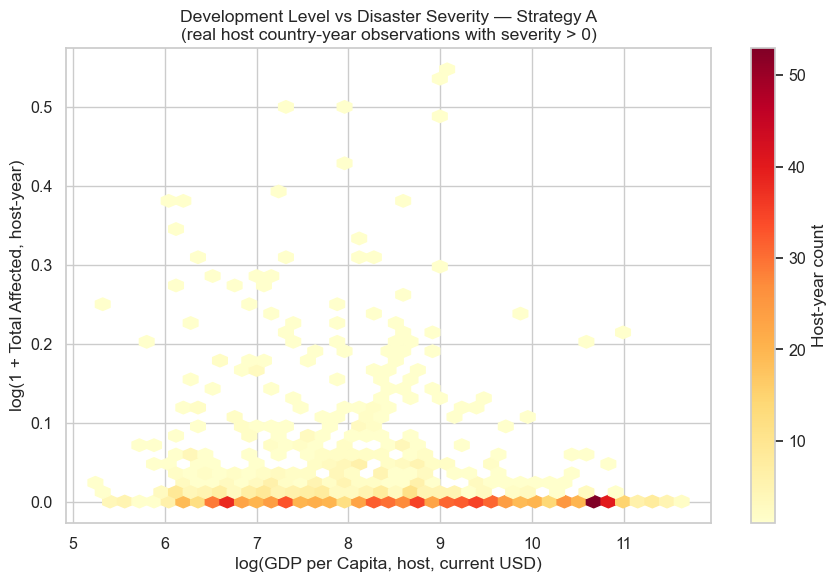

In [20]:
plot17 = df_strategy_a.copy()
plot17 = plot17[
    plot17['host_country'].str.len().eq(3) &
    plot17['host_country'].str.isalpha() &
    (plot17['severity_total'] > 0) &
    plot17['gdp_pc_host'].notna()
].drop_duplicates(subset=['host_country', 'year'])

plot17['log_sev'] = np.log1p(plot17['severity_total'])
plot17['log_gdp'] = np.log(plot17['gdp_pc_host'].clip(lower=1))

fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(
    plot17['log_gdp'], plot17['log_sev'],
    gridsize=40, cmap='YlOrRd', mincnt=1
)
cb = fig.colorbar(hb, ax=ax, label='Host-year count')
ax.set_xlabel('log(GDP per Capita, host, current USD)')
ax.set_ylabel('log(1 + Total Affected, host-year)')
ax.set_title(
    'Development Level vs Disaster Severity — Strategy A\n'
    '(real host country-year observations with severity > 0)'
)
plt.tight_layout()
plt.show()

---
## Part 5: Home Country & Network Effects (Institutional Learning)

### Graph 18: MNE Resilience by Home Country
**Title:** Average Δln(Employment) in Host-Country Crisis Years, by Home Country (Top 5)

**Hypothesis:** MNE nationality matters. Some parent countries (e.g., Germany, France) may have more resilient organisational and financial capabilities, translating into smaller affiliate employment drops during host-country crises.

Top 5 home countries by crisis-year observations: ['NLD', 'SWE', 'ITA', 'DNK', 'FRA']


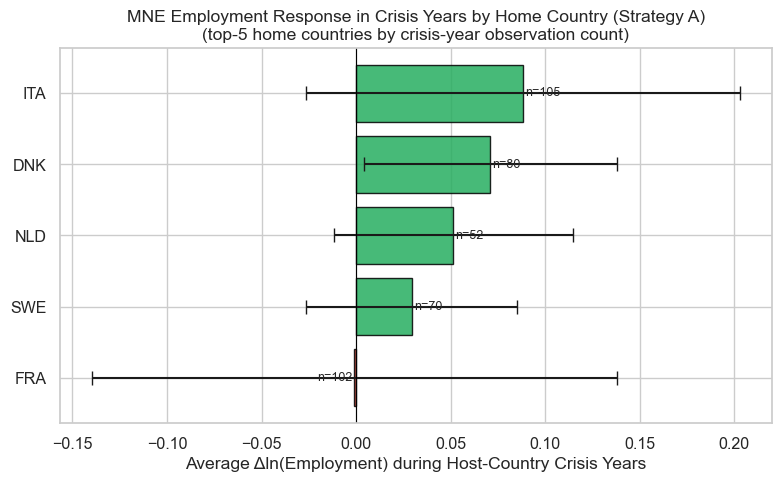

In [21]:
crisis_df = df_strategy_a[df_strategy_a['crisis_year'] == 1].copy()
top5_home = crisis_df['home_country'].value_counts().head(5).index.tolist()
print(f"Top 5 home countries by crisis-year observations: {top5_home}")

agg18 = (
    crisis_df[crisis_df['home_country'].isin(top5_home)]
    .groupby('home_country')['delta_ln_emp']
    .agg(['mean', 'sem', 'count'])
    .reset_index()
)
agg18.columns = ['home_country', 'mean', 'se', 'n']
agg18 = agg18.sort_values('mean')

fig, ax = plt.subplots(figsize=(8, 5))
for _, row in agg18.iterrows():
    color = '#c0392b' if row['mean'] < 0 else '#27ae60'
    ax.barh(row['home_country'], row['mean'], xerr=row['se'] * 1.96,
            capsize=5, color=color, alpha=0.85, edgecolor='black')
    ax.text(row['mean'] + (0.001 if row['mean'] >= 0 else -0.001),
            row['home_country'], f"n={row['n']:,}",
            va='center', ha='left' if row['mean'] >= 0 else 'right', fontsize=9)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Average Δln(Employment) during Host-Country Crisis Years')
ax.set_title(
    'MNE Employment Response in Crisis Years by Home Country (Strategy A)\n'
    '(top-5 home countries by crisis-year observation count)'
)
plt.tight_layout()
plt.show()

### Graph 19: Home Country Disaster Experience as Moderator
**Title:** Average Δln(Employment) by Crisis Status and Home Country Disaster History

**Hypothesis / Purpose:** Firms from countries with higher domestic disaster exposure (higher `hist_n_static_home`) develop institutional learning and better manage affiliates during crises in host countries.

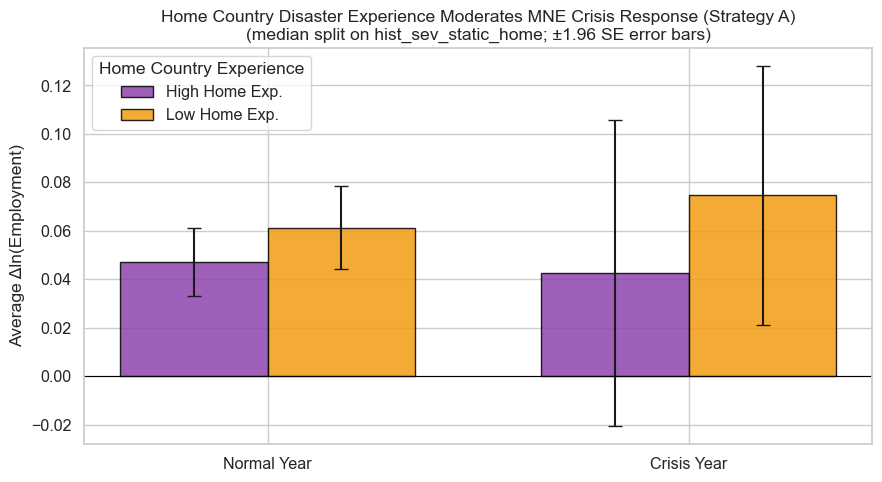

In [22]:
med_home_exp = df_strategy_a['hist_sev_static_home'].median()
df_strategy_a['home_exp_group'] = np.where(
    df_strategy_a['hist_sev_static_home'] >= med_home_exp, 'High Home Exp.', 'Low Home Exp.'
)

agg19 = (
    df_strategy_a.groupby(['crisis_label', 'home_exp_group'])['delta_ln_emp']
    .agg(['mean', 'sem'])
    .reset_index()
)
agg19.columns = ['Crisis', 'Home Experience', 'mean', 'se']

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(2)
width = 0.35
order = ['Normal Year', 'Crisis Year']
home_colors = {'High Home Exp.': '#8e44ad', 'Low Home Exp.': '#f39c12'}

for i, grp in enumerate(['High Home Exp.', 'Low Home Exp.']):
    sub = (
        agg19[agg19['Home Experience'] == grp]
        .set_index('Crisis')
        .reindex(order)
    )
    offset = (i - 0.5) * width
    ax.bar(x + offset, sub['mean'], width,
           yerr=sub['se'] * 1.96, capsize=5,
           label=grp, color=home_colors[grp], alpha=0.85, edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(order)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(
    'Home Country Disaster Experience Moderates MNE Crisis Response (Strategy A)\n'
    '(median split on hist_sev_static_home; ±1.96 SE error bars)'
)
ax.set_ylabel('Average Δln(Employment)')
ax.legend(title='Home Country Experience')
plt.tight_layout()
plt.show()

### Graph 20: Geographic Distance vs Affiliate Exit Post-Disaster
**Title:** Population-Weighted Distance (distw) vs % Change in Enterprises after a Crisis

**Hypothesis:** MNEs abandon geographically distant affiliates faster during a host-country crisis because monitoring costs are higher and switching costs lower for distant production sites.

Dyad-level aggregation: 602 (home, host) pairs in crisis years


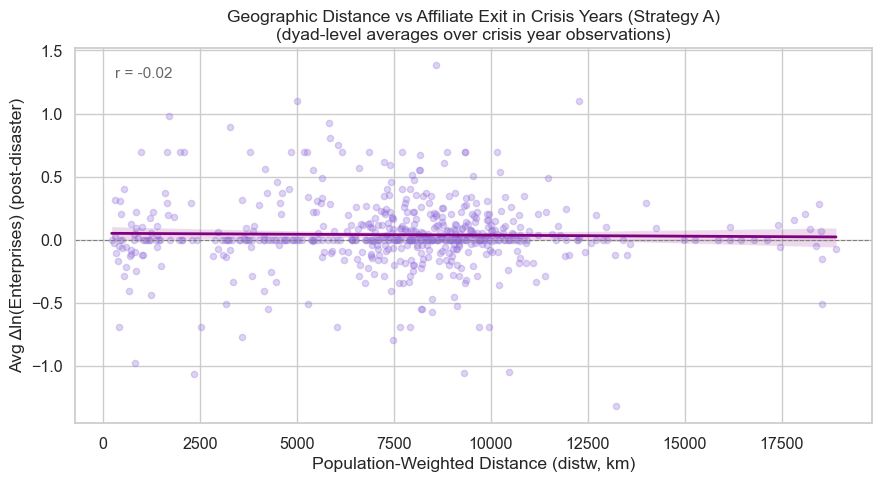

In [23]:
crisis_dy = (
    df_strategy_a[df_strategy_a['crisis_year'] == 1]
    .groupby(['home_country', 'host_country'])
    .agg(distw=('distw', 'mean'), pct_ent=('dln_ent', 'mean'), n=('distw', 'count'))
    .dropna()
    .reset_index()
)
crisis_dy = crisis_dy[
    crisis_dy['host_country'].str.len().eq(3) & crisis_dy['host_country'].str.isalpha()
]
print(f"Dyad-level aggregation: {len(crisis_dy):,} (home, host) pairs in crisis years")

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=crisis_dy, x='distw', y='pct_ent',
    scatter_kws={'alpha': 0.3, 's': 20, 'color': 'mediumpurple'},
    line_kws={'color': 'purple', 'linewidth': 2},
    ax=ax
)
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Population-Weighted Distance (distw, km)')
ax.set_ylabel('Avg Δln(Enterprises) (post-disaster)')
ax.set_title(
    'Geographic Distance vs Affiliate Exit in Crisis Years (Strategy A)\n'
    '(dyad-level averages over crisis year observations)'
)

corr20 = crisis_dy[['distw', 'pct_ent']].corr().iloc[0, 1]
ax.text(0.05, 0.95, f'r = {corr20:.2f}', transform=ax.transAxes,
        fontsize=11, va='top', color='dimgray')
plt.tight_layout()
plt.show()

### Graph 21: The MNE Experience Premium
**Title:** Severity of Host-Country Shock vs Δln(Employment), split by Home Country Disaster History

**Hypothesis / Purpose:** Firms from high-exposure home countries (high `hist_n_static_home`) maintain employment better as host shocks intensify — the “experience premium”.

None: n=5,911, mean Δln(emp) = 0.0453
Moderate: n=8,135, mean Δln(emp) = 0.0569
Severe: n=2,366, mean Δln(emp) = 0.0587


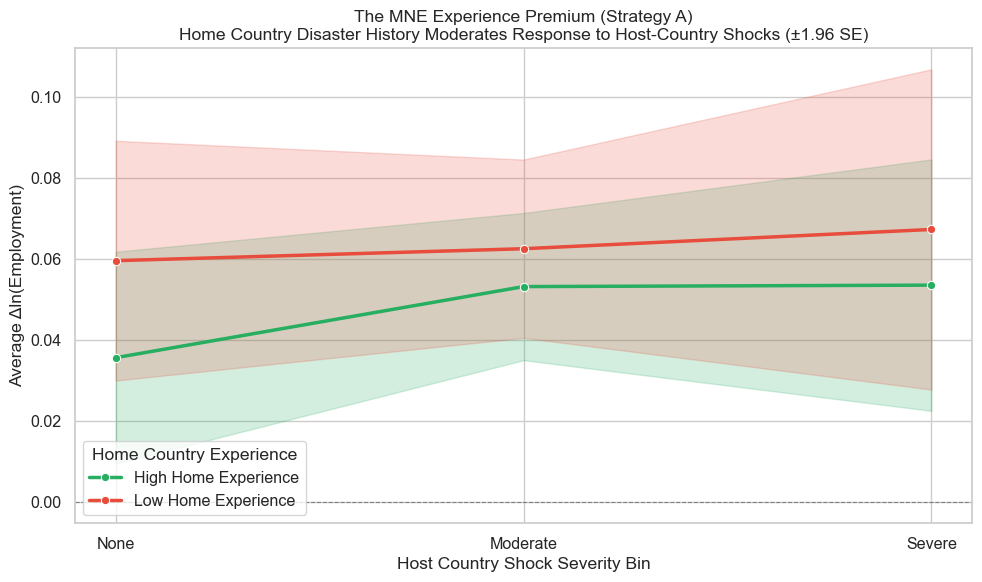

In [24]:
_nz_sev = df_strategy_a.loc[df_strategy_a['severity_total'] > 0, 'severity_total']
q75_sev = _nz_sev.quantile(0.75)

def sev_bin(x):
    if x == 0:
        return 'None'
    elif x <= q75_sev:
        return 'Moderate'
    else:
        return 'Severe'

df_strategy_a['shock_bin'] = df_strategy_a['severity_total'].apply(sev_bin)
df_strategy_a['shock_bin'] = pd.Categorical(
    df_strategy_a['shock_bin'], categories=['None', 'Moderate', 'Severe'], ordered=True
)

med_home_exp_21 = df_strategy_a['hist_sev_static_home'].median()
df_strategy_a['home_exp_line'] = np.where(
    df_strategy_a['hist_sev_static_home'] >= med_home_exp_21,
    'High Home Experience',
    'Low Home Experience'
)

plot21 = df_strategy_a.dropna(subset=['delta_ln_emp', 'hist_sev_static_home']).copy()

for grp in ['None', 'Moderate', 'Severe']:
    sub = plot21[plot21['shock_bin'] == grp]
    print(f"{grp}: n={len(sub):,}, mean Δln(emp) = {sub['delta_ln_emp'].mean():.4f}")

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=plot21,
    x='shock_bin', y='delta_ln_emp',
    hue='home_exp_line',
    estimator='mean',
    errorbar=('se', 1.96),
    marker='o', linewidth=2.5,
    palette={'High Home Experience': '#27ae60', 'Low Home Experience': '#e74c3c'},
    ax=ax
)
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('Host Country Shock Severity Bin')
ax.set_ylabel('Average Δln(Employment)')
ax.set_title(
    'The MNE Experience Premium (Strategy A)\n'
    'Home Country Disaster History Moderates Response to Host-Country Shocks (±1.96 SE)'
)
ax.legend(title='Home Country Experience', loc='lower left')
plt.tight_layout()
plt.show()

### Graph 22: Home Region × Shock Severity — Employment Response
**Title:** Do European Home Regions React Differently to Host-Country Disasters?

**Left panel:** Average Δln(Employment) across shock severity bins (None / Moderate / Severe) by home region — shows whether the disaster-response *gradient* differs across investor origins.

**Right panel:** Normal vs Crisis year employment growth by home region — the crisis *penalty* and how it varies by region.

**Hypothesis:** E. European and S. European MNEs may be more accustomed to operating in volatile environments (higher domestic disaster history; see Graph 16b), potentially damping their crisis response relative to W./N. European peers. Conversely, W. European MNEs may retract more sharply when exposed to unfamiliar host-country shocks.

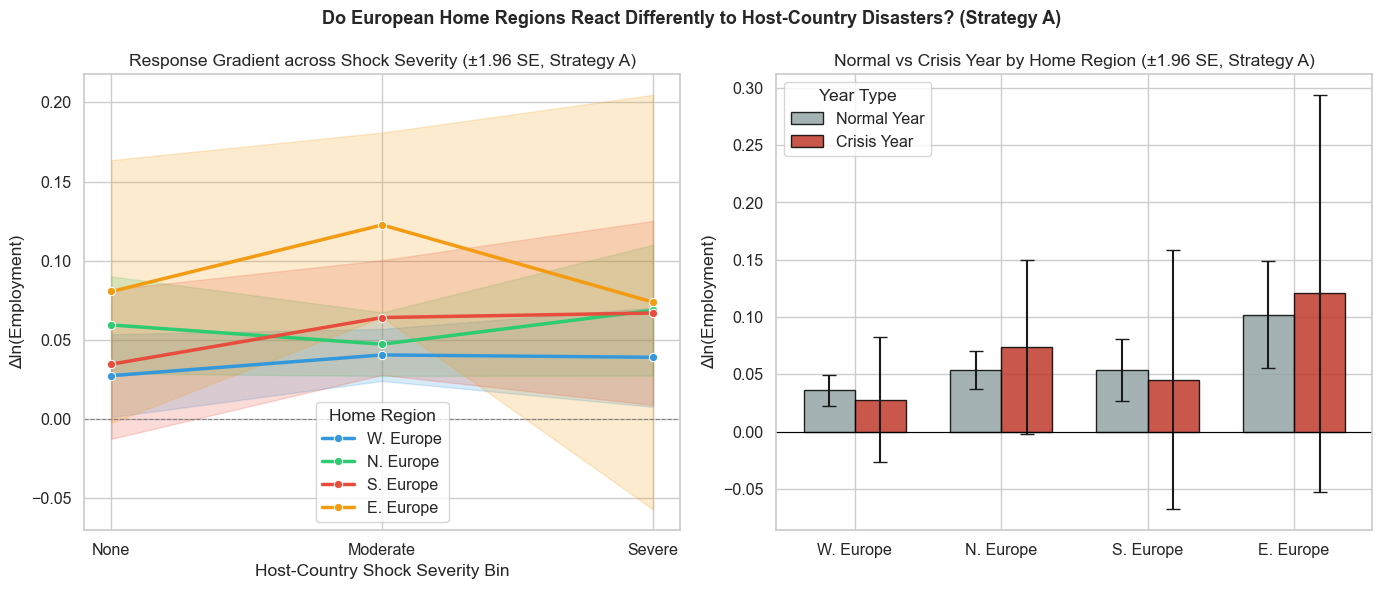

Mean delta_ln_emp by Home Region x Crisis Year:
                            mean     n
home_region crisis_label              
E. Europe   Crisis Year   0.1207    61
            Normal Year   0.1021  1327
N. Europe   Crisis Year   0.0741   358
            Normal Year   0.0536  5585
S. Europe   Crisis Year   0.0455   224
            Normal Year   0.0541  4086
W. Europe   Crisis Year   0.0279   323
            Normal Year   0.0361  4448

Crisis penalty (crisis mean - normal mean) per home region:
crisis_label  Normal Year  Crisis Year  penalty
home_region                                    
E. Europe          0.1021       0.1207   0.0186
N. Europe          0.0536       0.0741   0.0205
S. Europe          0.0541       0.0455  -0.0086
W. Europe          0.0361       0.0279  -0.0082


In [25]:
# === Graph 22: Employment response by home region x shock severity ===
region_order   = ["W. Europe", "N. Europe", "S. Europe", "E. Europe"]
region_palette = {"W. Europe": "#3498db", "N. Europe": "#2ecc71",
                  "S. Europe": "#e74c3c", "E. Europe": "#f39c12"}

# Reuse shock_bin from Graph 21 if present; else rebuild
if "shock_bin" not in df_strategy_a.columns:
    _nz = df_strategy_a.loc[df_strategy_a["severity_total"] > 0, "severity_total"]
    _q75 = _nz.quantile(0.75)
    df_strategy_a["shock_bin"] = pd.Categorical(
        df_strategy_a["severity_total"].map(
            lambda x: "None" if x == 0 else ("Moderate" if x <= _q75 else "Severe")
        ),
        categories=["None", "Moderate", "Severe"], ordered=True
    )

plot22 = (
    df_strategy_a
    .dropna(subset=["delta_ln_emp", "home_region"])
    [lambda d: d["home_region"].isin(region_order)]
    .copy()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Left: response gradient across shock severity ---
sns.lineplot(
    data=plot22,
    x="shock_bin", y="delta_ln_emp",
    hue="home_region", hue_order=region_order,
    estimator="mean", errorbar=("se", 1.96),
    marker="o", linewidth=2.5,
    palette=region_palette,
    ax=axes[0]
)
axes[0].axhline(0, color="gray", linewidth=0.8, linestyle="--")
axes[0].set_xlabel("Host-Country Shock Severity Bin")
axes[0].set_ylabel("Δln(Employment)")
axes[0].set_title("Response Gradient across Shock Severity (±1.96 SE, Strategy A)")
axes[0].legend(title="Home Region")

# --- Right: Normal vs Crisis year by region ---
agg22 = (
    plot22
    .groupby(["crisis_label", "home_region"])["delta_ln_emp"]
    .agg(["mean", "sem"])
    .reset_index()
)
agg22.columns = ["Crisis", "Region", "mean", "se"]

x     = np.arange(len(region_order))
width = 0.35
crisis_labels = ["Normal Year", "Crisis Year"]
crisis_colors = {"Normal Year": "#95a5a6", "Crisis Year": "#c0392b"}

for j, crisis in enumerate(crisis_labels):
    sub = (
        agg22[agg22["Crisis"] == crisis]
        .set_index("Region")
        .reindex(region_order)
    )
    offset = (j - 0.5) * width
    axes[1].bar(
        x + offset, sub["mean"], width,
        yerr=sub["se"] * 1.96, capsize=5,
        label=crisis,
        color=crisis_colors[crisis],
        alpha=0.85, edgecolor="black"
    )

axes[1].set_xticks(x)
axes[1].set_xticklabels(region_order)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Δln(Employment)")
axes[1].set_title("Normal vs Crisis Year by Home Region (±1.96 SE, Strategy A)")
axes[1].legend(title="Year Type")

fig.suptitle(
    "Do European Home Regions React Differently to Host-Country Disasters? (Strategy A)",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()

# Descriptive summary
print("Mean delta_ln_emp by Home Region x Crisis Year:")
tbl = (
    plot22
    .groupby(["home_region", "crisis_label"])["delta_ln_emp"]
    .agg(mean="mean", n="count")
    .round(4)
)
print(tbl)

print("")
print("Crisis penalty (crisis mean - normal mean) per home region:")
penalty = (
    tbl["mean"]
    .unstack("crisis_label")
    .assign(penalty=lambda d: d["Crisis Year"] - d["Normal Year"])
    [["Normal Year", "Crisis Year", "penalty"]]
)
print(penalty.round(4))